In [1]:
import sys
from pathlib import Path
raiz = Path.cwd()
while not (raiz / "src").exists() and raiz != raiz.parent:
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import numpy as np
import pandas as pd
from src.cuantizacion import cargar_modelos, transformar, ESTRATEGIAS

BASE = raiz / "resultados" / "actividad3"
COLS = ["edad", "ingresos", "altura"]
BINS = [5, 10, 25, 50]

In [2]:
res = pd.read_csv(BASE / "tablas" / "resultados_1M.csv")
assert len(res) == 72, len(res)
assert (res["n_filas"] == 1_000_000).all()
assert res["validacion_ok"].all()
assert (res["bins_reales"] <= res["bins_solicitados"]).all()
assert res[["mae", "rmse", "error_max"]].notna().all().all()
print("tabla OK:", res.shape)
print("NaN por columna (%):", res.groupby("columna")["pct_nan"].first().to_dict())
print("fuera de rango máx (%):", res["pct_fuera_rango"].max())
print("bins reales distintos de los solicitados:")
display(res[res["bins_reales"] != res["bins_solicitados"]][
    ["columna", "estrategia", "bins_solicitados", "bins_reales"]].drop_duplicates())

tabla OK: (72, 28)
NaN por columna (%): {'altura': 0.0, 'edad': 0.0, 'ingresos': 0.0}
fuera de rango máx (%): 0.0
bins reales distintos de los solicitados:


,columna,estrategia,bins_solicitados,bins_reales


In [3]:
df = pd.read_parquet(raiz / "data" / "dataset_1M.parquet", columns=COLS)
for estr in ESTRATEGIAS:
    for k in BINS:
        modelos = cargar_modelos(BASE / "modelos" / "1M" / f"{estr}_{k}.json")
        guardados = pd.read_parquet(BASE / "datos_cuantizados" / "1M" / f"codigos_{estr}_{k}.parquet")
        assert len(guardados) == len(df)
        for c in COLS:
            nuevo = transformar(df[c], modelos[c])
            assert np.array_equal(nuevo, guardados[c].to_numpy()), (estr, k, c)
print("OK: los 8 JSON reproducen exactamente los códigos guardados")

OK: los 8 JSON reproducen exactamente los códigos guardados


In [4]:
tam = (res.groupby(["estrategia", "bins_solicitados"])["tam_codigos_MB"].first().round(2)
       .rename("codigos_parquet_MB").reset_index())
print("original en memoria (3 columnas float64):", round(df.memory_usage().sum() / 1e6, 1), "MB")
print("códigos int16 en memoria (3 columnas):   ", round(1_000_000 * 3 * 2 / 1e6, 1), "MB")
tam

original en memoria (3 columnas float64): 24.0 MB
códigos int16 en memoria (3 columnas):    6.0 MB


,estrategia,bins_solicitados,codigos_parquet_MB
0,cuantiles,5,1.01
1,cuantiles,10,1.27
2,cuantiles,25,1.88
3,cuantiles,50,2.26
4,uniforme,5,0.50
5,uniforme,10,0.73
6,uniforme,25,1.46
7,uniforme,50,1.83


In [5]:
for rep in ("punto_medio", "media", "mediana"):
    print("\n== MAE con", rep)
    display(res[res["representante"] == rep]
            .pivot_table(index=["columna", "estrategia"], columns="bins_solicitados", values="mae").round(4))

print("\n== error máximo con representante media")
display(res[res["representante"] == "media"]
        .pivot_table(index=["columna", "estrategia"], columns="bins_solicitados", values="error_max").round(2))
print("\ndif. máxima de correlación por estrategia y bins:")
display(res.groupby(["estrategia", "bins_solicitados"])["dif_corr_max"].first().round(6))


== MAE con punto_medio


bins_solicitados             5          10         25         50
columna  estrategia                                             
altura   cuantiles       6.9563     3.4281     1.3341     0.6509
         uniforme        4.9791     2.5027     1.0019     0.5000
edad     cuantiles       7.7532     3.8165     1.4817     0.7230
         uniforme        5.6906     2.8521     1.1419     0.5708
ingresos cuantiles   20432.3393  9996.8881  3867.6621  1877.3401
         uniforme     9216.3344  5527.2657  2451.7141  1219.9089


== MAE con media


bins_solicitados            5          10         25         50
columna  estrategia                                            
altura   cuantiles      2.3004     1.2747     0.5711     0.3065
         uniforme       4.1994     2.3746     0.9928     0.4988
edad     cuantiles      2.7620     1.5330     0.6854     0.3681
         uniforme       4.8441     2.7186     1.1330     0.5696
ingresos cuantiles   3147.6880  1827.9291   872.4176   491.7184
         uniforme    8071.5108  4702.7781  2274.3398  1196.3019


== MAE con mediana


bins_solicitados            5          10         25         50
columna  estrategia                                            
altura   cuantiles      2.2536     1.2508     0.5617     0.3021
         uniforme       4.1682     2.3629     0.9918     0.4987
edad     cuantiles      2.7052     1.5044     0.6743     0.3628
         uniforme       4.8054     2.7060     1.1319     0.5695
ingresos cuantiles   3025.3773  1763.4050   843.5349   477.0237
         uniforme    7953.4994  4664.1838  2267.4439  1194.6484


== error máximo con representante media


bins_solicitados            5          10         25         50
columna  estrategia                                            
altura   cuantiles       36.34      32.79      28.81      26.13
         uniforme        17.19       7.33       2.73       1.19
edad     cuantiles       41.14      36.87      32.06      28.85
         uniforme        19.47       8.83       3.02       1.38
ingresos cuantiles   200424.52  191894.82  180224.98  170981.62
         uniforme     37415.55   16101.20    7386.42    3827.93


dif. máxima de correlación por estrategia y bins:


estrategia  bins_solicitados
cuantiles   5                   0.000786
            10                  0.000303
            25                  0.000590
            50                  0.000435
uniforme    5                   0.000369
            10                  0.000616
            25                  0.000242
            50                  0.000063
Name: dif_corr_max, dtype: float64

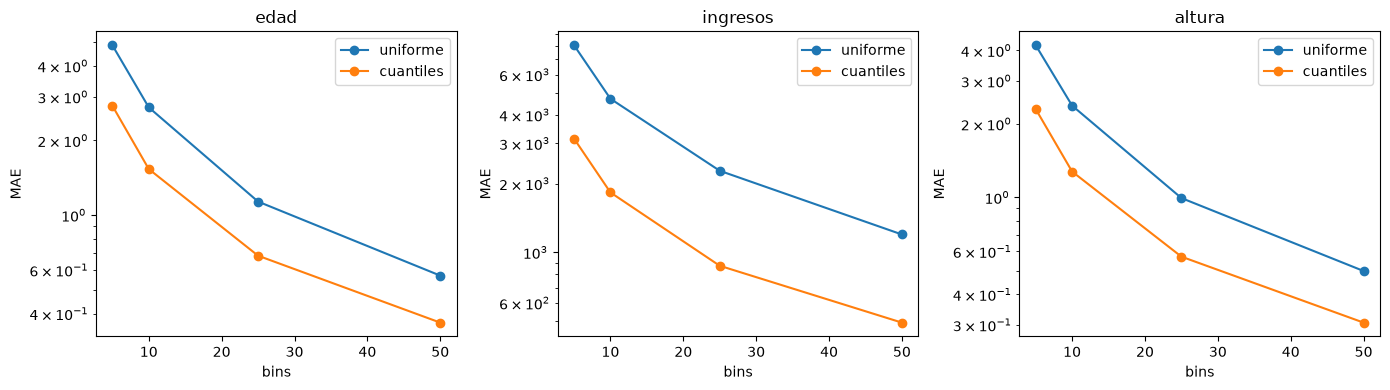

In [6]:
import matplotlib.pyplot as plt
(BASE / "graficos").mkdir(parents=True, exist_ok=True)
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(ejes, COLS):
    for estr in ESTRATEGIAS:
        s = res[(res["columna"] == c) & (res["estrategia"] == estr) & (res["representante"] == "media")]
        ax.plot(s["bins_solicitados"], s["mae"], marker="o", label=estr)
    ax.set_title(c); ax.set_xlabel("bins"); ax.set_ylabel("MAE"); ax.set_yscale("log"); ax.legend()
fig.tight_layout()
fig.savefig(BASE / "graficos" / "mae_vs_bins_1M.png", dpi=130)